# Bayesian Network for Hospital Readmission Prediction

The objective of this analysis is to develop a Bayesian Network model to predict whether a patient will be readmitted to the hospital based on demographic information, medical history, diagnoses, medications, and hospitalization characteristics. All available variables will initially be considered to identify potential probabilistic relationships with hospital readmission. The model will then be evaluated to determine which variables are most strongly associated with readmission and how accurately the network can predict patient outcomes.

We'll use Pandas and NumPy for data preparation, Matplotlib and NetworkX for visualization, and pgmpy for Bayesian Network modeling.

# Step 1. Loading the Dataset

The cleaned hospital dataset was imported directly from the GitHub repository using Pandas. A separate copy of the dataset was created for the Bayesian Network analysis to preserve the original data. The dataset contains information about patient demographics, hospital admissions, medical procedures, diagnoses, medications, and readmission outcomes.

In [1]:
# Install required library
%pip install -q pandas numpy matplotlib networkx pgmpy scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.estimators import PC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# GitHub cleaned dataset
url = "https://raw.githubusercontent.com/mvillarreal-usd/FinalTeamProjectAAI-500/refs/heads/cleaning-of-the-database/cleaned_database.csv"

# Loading the cleaned dataset
df = pd.read_csv(url)

# Creating the Bayesian Network analysis dataset
bn_data = df.copy()

print(f"Observations: {bn_data.shape[0]}")
print(f"Variables: {bn_data.shape[1]}")

# Displaying the dataset
display(bn_data.head())


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\manue\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


C:\Users\manue\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Observations: 101766
Variables: 35


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,...,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),6,25,1,1,Pediatrics-Endocrinology,41,0,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),1,1,7,3,NaN,59,0,...,No,No,No,No,No,Up,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,11,5,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),1,1,7,2,NaN,44,1,...,No,No,No,No,No,Up,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),1,1,7,1,NaN,51,0,...,No,No,No,No,No,Steady,No,Ch,Yes,NO


# Step 2. Target Variable Preparation

The readmitted variable was converted into binary classification to predict whether a patient would be readmitted to the hospital. Patients with no recorded readmission (NO) were assigned a value of 0, while patients readmitted within 30 days (<30) or after 30 days (>30) were assigned a value of 1. This allows the Bayesian Network to focus on predicting overall hospital readmission rather than the specific time of readmission.

In [2]:
# Checking the original readmission categories
print("Original readmission distribution:")
print(bn_data['readmitted'].value_counts())

# Binary classification mapping for Readmission variable
readmission_mapping = {
    'NO': 0,
    '<30': 1,
    '>30': 1
}

# Converting the target variable
bn_data['readmitted'] = (
    bn_data['readmitted'].map(readmission_mapping)
)

# Validating the target variable
if bn_data['readmitted'].isna().any():
    raise ValueError("Unexpected readmission values found.")

bn_data['readmitted'] = bn_data['readmitted'].astype(int)

# Displaying the new distribution
readmission_summary = pd.DataFrame({
    'Count': bn_data['readmitted'].value_counts(),
    'Percentage (%)': (
        bn_data['readmitted']
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(readmission_summary)

Original readmission distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


,Count,Percentage (%)
readmitted,,
0,54864,53.91
1,46902,46.09


# Step 3. Predictor Variable Exploration

All 34 predictor variables were initially considered for the Bayesian Network analysis. Each variable was examined based on its data type, number of unique values, and missing observations. This helps identify variables that may require additional preprocessing before structure learning, particularly numerical variables and categorical variables with many unique values. One example of this is the medical_specialty predictor. During the cleaning of the database we decided to keep this variable as it might have some relationship with hospital readmissions. Therefore, this predictor will be handled with replacing the missing values as unknown and seeing if it has any relationship at all.

In [3]:
# Selecting all the predictors (We can modify this section in case we only want certain predictors instead of everything)
predictor_columns = [
    col for col in bn_data.columns
    if col != 'readmitted'
]

# Summarizing the predictors
variable_summary = pd.DataFrame({
    'Variable': predictor_columns,
    'Data Type': [
        str(bn_data[col].dtype)
        for col in predictor_columns
    ],
    'Unique Values': [
        bn_data[col].nunique(dropna=True)
        for col in predictor_columns
    ],
    'Missing Values': [
        bn_data[col].isna().sum()
        for col in predictor_columns
    ],
    'Missing (%)': [
        bn_data[col].isna().mean() * 100
        for col in predictor_columns
    ]
})

print(f"Total predictors: {len(predictor_columns)}")

display(variable_summary.round(2))

Total predictors: 34


,Variable,Data Type,Unique Values,Missing Values,Missing (%)
0,race,object,5,2273,2.23
1,gender,object,3,0,0.00
2,age,object,10,0,0.00
3,admission_type_id,int64,8,0,0.00
4,discharge_disposition_id,int64,26,0,0.00
5,admission_source_id,int64,17,0,0.00
6,time_in_hospital,int64,14,0,0.00
7,medical_specialty,object,72,49949,49.08
8,num_lab_procedures,int64,118,0,0.00
9,num_procedures,int64,7,0,0.00


# Step 4. Exploring the Dataset

The dataset was examined to identify the data types, number of unique values, and missing observations for each variable. This analysis helped distinguish numerical variables from categorical variables and identify columns requiring additional preprocessing. Understanding the distribution and structure of the variables is important before applying a Bayesian Network because variables with many states can increase model complexity.

In [4]:
# Creating the variable summary
variable_summary = pd.DataFrame({
    'Variable': bn_data.columns,
    'Data Type': bn_data.dtypes.astype(str).values,
    'Unique Values': [
        bn_data[col].nunique(dropna=True)
        for col in bn_data.columns
    ],
    'Missing Values': bn_data.isna().sum().values,
    'Missing Percentage': (
        bn_data.isna().mean().values * 100
    )
})

# Sort by missing percentage
variable_summary = variable_summary.sort_values(
    'Missing Percentage',
    ascending=False
)

display(variable_summary)


,Variable,Data Type,Unique Values,Missing Values,Missing Percentage
7,medical_specialty,object,72,49949,49.082208
0,race,object,5,2273,2.233555
16,diag_3,object,789,1423,1.398306
15,diag_2,object,748,358,0.351787
14,diag_1,object,716,21,0.020636
2,age,object,10,0,0.000000
1,gender,object,3,0,0.000000
6,time_in_hospital,int64,14,0,0.000000
3,admission_type_id,int64,8,0,0.000000
5,admission_source_id,int64,17,0,0.000000


# Step 5. Handling Missing Values

Missing values were identified and prepared for the Bayesian Network analysis. The medical_specialty variable was retained despite having approximately 49% missing values because it may contain useful information about hospital readmissions. Missing medical specialties were assigned an Unknown category, allowing us to preserve the observations and investigate whether specialty information is associated with readmission.

All the other missing values will be handled the same way, for example we have a couple missing values for the "race" predictor that will be handled and filled with "Unknown" as well.

In [5]:
# Standardizing the "missing value" placeholders
bn_data = bn_data.replace(
    ['?', 'Unknown/Invalid'],
    np.nan
)

# Variables with missing categorical information
missing_columns = [
    'race',
    'gender',
    'medical_specialty',
    'diag_1',
    'diag_2',
    'diag_3'
]

# Displaying missing values before replacement
print("Missing values before:")
print(bn_data[missing_columns].isna().sum())


# Replace missing categorical values with Unknown
for column in missing_columns:
    bn_data[column] = (
        bn_data[column].fillna('Unknown')
    )

# Verifying that the predictors have 0 missing values
print("\nMissing values after:")
print(bn_data[missing_columns].isna().sum())

Missing values before:
race                  2273
gender                   3
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
dtype: int64

Missing values after:
race                 0
gender               0
medical_specialty    0
diag_1               0
diag_2               0
diag_3               0
dtype: int64


# Step 6. Grouping Diagnosis Codes for diag_1, 2, and 3 predictors.

The three diagnosis variables (diag_1, diag_2, and diag_3) were grouped into broader medical categories using the 2015 ICD-9-CM classification system (ICD9Data.com, n.d.). This classification organizes diagnosis codes into categories such as circulatory diseases, respiratory diseases, endocrine disorders, and infectious diseases. Grouping the codes reduces the number of unique values and simplifies the Bayesian Network while preserving information about the types of medical conditions associated with each patient. This will allow us to investigate whether certain diagnosis categories have stronger statistical relationships with hospital readmission.

Reference
<br>
ICD9Data.com. (n.d.). 2015 ICD-9-CM diagnosis codes. https://www.icd9data.com/2015/Volume1/default.htm

In [6]:
# Creating the function to map the diag_1, 2, and 3 predictors into simpler values to reduce the amount of unique values in each of the variables.
def group_diagnosis(code):

    if pd.isna(code):
        return 'Unknown'

    code = str(code).strip().upper()

    if code in ['', '?', 'UNKNOWN', 'NAN']:
        return 'Unknown'

    # Supplementary ICD-9-CM classifications
    if code.startswith('V'):
        return 'Supplementary Health Factors'

    if code.startswith('E'):
        return 'External Causes'

    # Converting the diagnosis code to numerical values
    try:
        value = float(code)
    except ValueError:
        return 'Unknown'

    # ICD-9-CM diagnosis categories
    if 1 <= value < 140:
        return 'Infectious and Parasitic Diseases'

    elif 140 <= value < 240:
        return 'Neoplasms'

    elif 240 <= value < 280:
        return 'Endocrine and Metabolic Diseases'

    elif 280 <= value < 290:
        return 'Blood Diseases'

    elif 290 <= value < 320:
        return 'Mental Disorders'

    elif 320 <= value < 390:
        return 'Nervous System Diseases'

    elif 390 <= value < 460:
        return 'Circulatory System Diseases'

    elif 460 <= value < 520:
        return 'Respiratory System Diseases'

    elif 520 <= value < 580:
        return 'Digestive System Diseases'

    elif 580 <= value < 630:
        return 'Genitourinary System Diseases'

    elif 630 <= value < 680:
        return 'Pregnancy and Childbirth'

    elif 680 <= value < 710:
        return 'Skin Diseases'

    elif 710 <= value < 740:
        return 'Musculoskeletal Diseases'

    elif 740 <= value < 760:
        return 'Congenital Anomalies'

    elif 760 <= value < 780:
        return 'Perinatal Conditions'

    elif 780 <= value < 800:
        return 'Symptoms and Ill-Defined Conditions'

    elif 800 <= value < 1000:
        return 'Injury and Poisoning'

    else:
        return 'Unknown'


# Applying the mapping to all three diagnosis columns
diagnosis_columns = ['diag_1', 'diag_2', 'diag_3']

for column in diagnosis_columns:
    bn_data[column] = bn_data[column].apply(group_diagnosis)

# Displaying the category distributions
for column in diagnosis_columns:
    print(f"\nDiagnosis categories for {column}")

    display(
        bn_data[column]
        .value_counts()
        .to_frame(name='Count')
    )


Diagnosis categories for diag_1


,Count
diag_1,
Circulatory System Diseases,30336
Endocrine and Metabolic Diseases,11459
Respiratory System Diseases,10407
Digestive System Diseases,9208
Symptoms and Ill-Defined Conditions,7636
Injury and Poisoning,6974
Genitourinary System Diseases,5078
Musculoskeletal Diseases,4957
Neoplasms,3433



Diagnosis categories for diag_2


,Count
diag_2,
Circulatory System Diseases,31365
Endocrine and Metabolic Diseases,21017
Respiratory System Diseases,10251
Genitourinary System Diseases,7987
Symptoms and Ill-Defined Conditions,4632
Digestive System Diseases,3962
Skin Diseases,3596
Blood Diseases,2926
Mental Disorders,2657



Diagnosis categories for diag_3


,Count
diag_3,
Circulatory System Diseases,29918
Endocrine and Metabolic Diseases,26308
Respiratory System Diseases,6774
Genitourinary System Diseases,6327
Symptoms and Ill-Defined Conditions,4523
Supplementary Health Factors,3814
Digestive System Diseases,3572
Mental Disorders,3136
Blood Diseases,2490


# Step 7. Training and Testing Split

The cleaned dataset was divided into training and testing sets using an 80/20 split. Stratified sampling was applied to maintain similar proportions of readmitted and non-readmitted patients in both datasets. The training set will be used to learn the Bayesian Network structure and estimate conditional probabilities, while the testing set will be used to evaluate the model's predictive performance.

In [7]:
from sklearn.model_selection import train_test_split

# Split into training and testing sets
train_bn, test_bn = train_test_split(
    bn_data,
    test_size=0.20,
    random_state=42,
    stratify=bn_data['readmitted']
)

# Create independent copies
train_bn = train_bn.copy()
test_bn = test_bn.copy()

print(f"Training observations: {len(train_bn)}")
print(f"Testing observations: {len(test_bn)}")

print("\nTraining readmission distribution:")
print(
    train_bn['readmitted']
    .value_counts(normalize=True)
    .round(3)
)

print("\nTesting readmission distribution:")
print(
    test_bn['readmitted']
    .value_counts(normalize=True)
    .round(3)
)

Training observations: 81412
Testing observations: 20354

Training readmission distribution:
readmitted
0    0.539
1    0.461
Name: proportion, dtype: float64

Testing readmission distribution:
readmitted
0    0.539
1    0.461
Name: proportion, dtype: float64


# Step 8. Discretizing Numerical Variables

The numerical variables were converted into categorical groups to make them compatible with a discrete Bayesian Network. Variables such as hospital stay duration, medication count, and previous hospital visits were divided into ranges based on their values. Missing numerical values, if present, were replaced using the training set median to avoid using information from the testing data during preprocessing.

In [8]:
# Numerical discretization configuration
bin_config = {
    'time_in_hospital': (
        [-np.inf, 3, 7, np.inf],
        ['Short', 'Medium', 'Long']
    ),
    'num_lab_procedures': (
        [-np.inf, 30, 60, np.inf],
        ['Low', 'Medium', 'High']
    ),
    'num_procedures': (
        [-np.inf, 0, 2, np.inf],
        ['None', 'Low', 'High']
    ),
    'num_medications': (
        [-np.inf, 10, 20, np.inf],
        ['Low', 'Medium', 'High']
    ),
    'number_outpatient': (
        [-np.inf, 0, 1, np.inf],
        ['None', 'One', 'Multiple']
    ),
    'number_emergency': (
        [-np.inf, 0, 1, np.inf],
        ['None', 'One', 'Multiple']
    ),
    'number_inpatient': (
        [-np.inf, 0, 1, np.inf],
        ['None', 'One', 'Multiple']
    ),
    'number_diagnoses': (
        [-np.inf, 5, 8, np.inf],
        ['Low', 'Medium', 'High']
    )
}

# Applying identical categories to both datasets
for column, (bins, labels) in bin_config.items():

    # Calculating the median using the training data dataset only
    median = pd.to_numeric(
        train_bn[column],
        errors='coerce'
    ).median()

    for dataset in [train_bn, test_bn]:

        values = pd.to_numeric(
            dataset[column],
            errors='coerce'
        ).fillna(median)

        dataset[column] = pd.cut(
            values,
            bins=bins,
            labels=labels
        ).astype(str)

display(train_bn.head())

,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,...,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,readmitted
25118,AfricanAmerican,Female,[50-60),1,1,7,Medium,Family/GeneralPractice,High,Low,...,No,No,No,No,No,No,No,No,No,1
63601,Caucasian,Female,[70-80),1,1,7,Medium,Unknown,Medium,High,...,No,No,No,No,No,Steady,No,No,Yes,1
19781,Caucasian,Male,[60-70),5,3,17,Short,Orthopedics-Reconstructive,Low,Low,...,No,No,No,No,No,No,No,Ch,Yes,0
94149,Caucasian,Male,[80-90),1,1,7,Short,Unknown,Medium,None,...,No,No,No,No,No,No,No,No,Yes,0
68161,Caucasian,Female,[70-80),5,3,1,Medium,Unknown,High,Low,...,No,No,No,No,No,Up,No,Ch,Yes,0


# Step 9. Grouping Rare Categorical Values

After handling missing values and grouping diagnosis codes in the previous steps, the medical_specialty variable was examined for uncommon categories. Specialties appearing fewer than 200 times in the training dataset were grouped into an Other category, while missing values remained classified as Unknown. This reduces the number of states in the Bayesian Network while preserving the original ICD-9 diagnosis categories and other patient information.

In [9]:
# Identifying the categorical predictors
categorical_columns = [
    col for col in train_bn.columns
    if col not in bin_config
    and col != 'readmitted'
]

# Preserve ICD-9 diagnosis categories
diagnosis_columns = ['diag_1', 'diag_2', 'diag_3']

# Grouping rare categories only in medical_specialty
column = 'medical_specialty'

# Minimum observations to preserve a specialty
min_frequency = 200

# Counting the specialties in training data
counts = train_bn[column].value_counts()

# Identifing the specialties times its used
frequent_categories = set(
    counts[counts >= min_frequency].index
)

# Preserving the "Unknown" value
frequent_categories.add('Unknown')

# Identifying the specialties that will be grouped into Other
other_categories = counts[
    (counts < min_frequency) &
    (counts.index != 'Unknown')
]

print("Medical specialties grouped into Other:")

display(
    other_categories.to_frame(name='Count')
)

print(f"\nTotal specialties grouped: {len(other_categories)}")
print(f"Total observations affected: {other_categories.sum()}")


# Grouping the uncommon specialties into "Other" category
train_bn[column] = train_bn[column].where(
    train_bn[column].isin(frequent_categories),
    'Other'
)

test_bn[column] = test_bn[column].where(
    test_bn[column].isin(frequent_categories),
    'Other'
)

# Displaying the resulting number of states for each variable, as multiple variables have different meanings based on codes or IDs used
category_summary = pd.DataFrame({
    'Variable': train_bn.columns,
    'Number of States': [
        train_bn[col].nunique()
        for col in train_bn.columns
    ]
})

display(
    category_summary.sort_values(
        'Number of States',
        ascending=False
    )
)
# Displaying the final states for medical_specialty predictor and their counts
print("\nMedical specialty distribution:")
display(
    train_bn['medical_specialty']
    .value_counts()
    .to_frame('Count')
)

Medical specialties grouped into Other:


,Count
medical_specialty,
Hematology/Oncology,174
Neurology,145
Pediatrics-Endocrinology,125
Otolaryngology,110
Endocrinology,94
Surgery-Thoracic,86
Podiatry,81
Psychology,76
Surgery-Cardiovascular,72



Total specialties grouped: 48
Total observations affected: 1612


,Variable,Number of States
4,discharge_disposition_id,26
7,medical_specialty,22
15,diag_2,19
16,diag_3,19
14,diag_1,19
5,admission_source_id,17
2,age,10
3,admission_type_id,8
0,race,6
27,acarbose,4



Medical specialty distribution:


,Count
medical_specialty,
Unknown,40040
InternalMedicine,11675
Emergency/Trauma,6073
Family/GeneralPractice,5969
Cardiology,4261
Surgery-General,2491
Other,1612
Nephrology,1311
Orthopedics,1125


# Step 10. Data Validation

The training and testing datasets were examined for missing values, variables with only one state, and categorical values not represented in the training data. All variables were converted into categorical strings for Bayesian Network modeling. Any unseen testing categories like tolazamide = 'up' were identified and handled using values supported by the training dataset to prevent errors during model evaluation.

In [19]:
# Checking the remaining missing values
print("Missing values in training data:")
display(
    train_bn.isna().sum()[
        train_bn.isna().sum() > 0
    ]
)

# Checking the variables with only one state
constant_columns = [
    col for col in train_bn.columns
    if train_bn[col].nunique() <= 1
]

print("\nVariables with only one state:")
print(constant_columns)

# Removing constant predictors
constant_columns = [
    col for col in constant_columns
    if col != 'readmitted'
]

train_bn = train_bn.drop(columns=constant_columns)
test_bn = test_bn.drop(columns=constant_columns)

# Converting all variables to categorical strings
train_bn = train_bn.astype(str)
test_bn = test_bn.astype(str)

# Check testing categories not present in training
unseen_states = {}

for column in train_bn.columns:
    train_states = set(train_bn[column].unique())
    test_states = set(test_bn[column].unique())

    unseen = test_states - train_states

    if unseen:
        unseen_states[column] = sorted(unseen)

print("\nUnseen testing states:")
print(unseen_states)

print("\nTraining shape:", train_bn.shape)
print("Testing shape:", test_bn.shape)

#Since the ouput showed us that we have a state in the test state but not in the training set for tolazamide = 'up' we would need to resolve it with a training fallback state.
for column, states in unseen_states.items():

    # Use most common training state as fallback
    fallback = train_bn[column].mode().iloc[0]

    test_bn[column] = test_bn[column].replace(
        states,
        fallback
    )

    print(
        f"{column}: {states} mapped to {fallback}"
    )

# Verifying again
remaining_unseen = {
    col: sorted(set(test_bn[col]) - set(train_bn[col]))
    for col in train_bn.columns
    if set(test_bn[col]) - set(train_bn[col])
}

print("\nRemaining unseen states:", remaining_unseen)

Missing values in training data:


Series([], dtype: int64)


Variables with only one state:
[]

Unseen testing states:
{}

Training shape: (81412, 35)
Testing shape: (20354, 35)

Remaining unseen states: {}


In [20]:
import inspect
from pgmpy.estimators import PC

print(inspect.signature(PC.estimate))

(self, variant: str = 'parallel', ci_test: str | collections.abc.Callable | None = None, return_type: str = 'pdag', significance_level: float = 0.01, max_cond_vars: int = 5, expert_knowledge: pgmpy.causal_discovery.ExpertKnowledge.ExpertKnowledge | None = None, enforce_expert_knowledge: bool = False, n_jobs: int = -1, show_progress: bool = True, **kwargs) -> pgmpy.base.DAG.DAG | pgmpy.base.PDAG.PDAG | tuple[networkx.classes.graph.Graph, dict[tuple[str, str], set[str]]]


# Step 11. Bayesian Network Structure Learning

The PC algorithm was used to identify conditional dependencies between variables in the training dataset. Statistical independence tests were performed using a significance level of 0.01 and a maximum conditioning set size of two. The resulting network represents potential statistical relationships between patient characteristics and hospital readmission.

In [21]:
from pgmpy.estimators import PC
import time

# Initialize PC algorithm
pc = PC(train_bn)

print("Starting PC algorithm...", flush=True)

start_time = time.time()

pc_model = pc.estimate(
    variant='stable',
    ci_test='chi_square',
    significance_level=0.01,
    max_cond_vars=2,
    return_type='dag',
    show_progress=True
)

print("\nStructure learning completed!")
print(f"Execution time: {time.time() - start_time:.2f} seconds")
print("Number of nodes:", len(pc_model.nodes()))
print("Number of edges:", len(pc_model.edges()))

C:\Users\manue\AppData\Local\Temp\ipykernel_4824\4064509797.py:5: FutureWarning: PC is deprecated and will be removed in v1.3.0. Please use pgmpy.causal_discovery.PC instead.
  pc = PC(train_bn)


Starting PC algorithm...


  0%|          | 0/2 [00:00<?, ?it/s]

C:\Users\manue\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pgmpy\estimators\BaseConstraintEstimator.py:219: FutureWarning: `chi_square` is deprecated and will be removed in v1.3.0. Please use `pgmpy.ci_tests.ChiSquare` instead.
  if ci_test(
C:\Users\manue\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pgmpy\estimators\CITests.py:425: FutureWarning: `power_divergence` is deprecated and will be removed in v1.3.0. Please use `pgmpy.ci_tests.PowerDivergence`
        instead.
  return power_divergence(X=X, Y=Y, Z=Z, data=data, boolean=boolean, lambda_="pearson", **kwargs)
C:\Users\manue\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pgmpy\estimators\BaseConstraintEstimator.py:219: FutureWarning: `chi_square` is deprecated and will be removed in v1.3.0. Please 

KeyboardInterrupt: 

# Step 12. Bayesian Network Visualization

The learned Bayesian Network will be visualized using NetworkX to examine the statistical relationships between variables. The readmitted variable was highlighted to identify its direct connections with patient characteristics. Relationships involving medical_specialty were also examined to investigate whether medical specialty information is connected to other variables in the network.

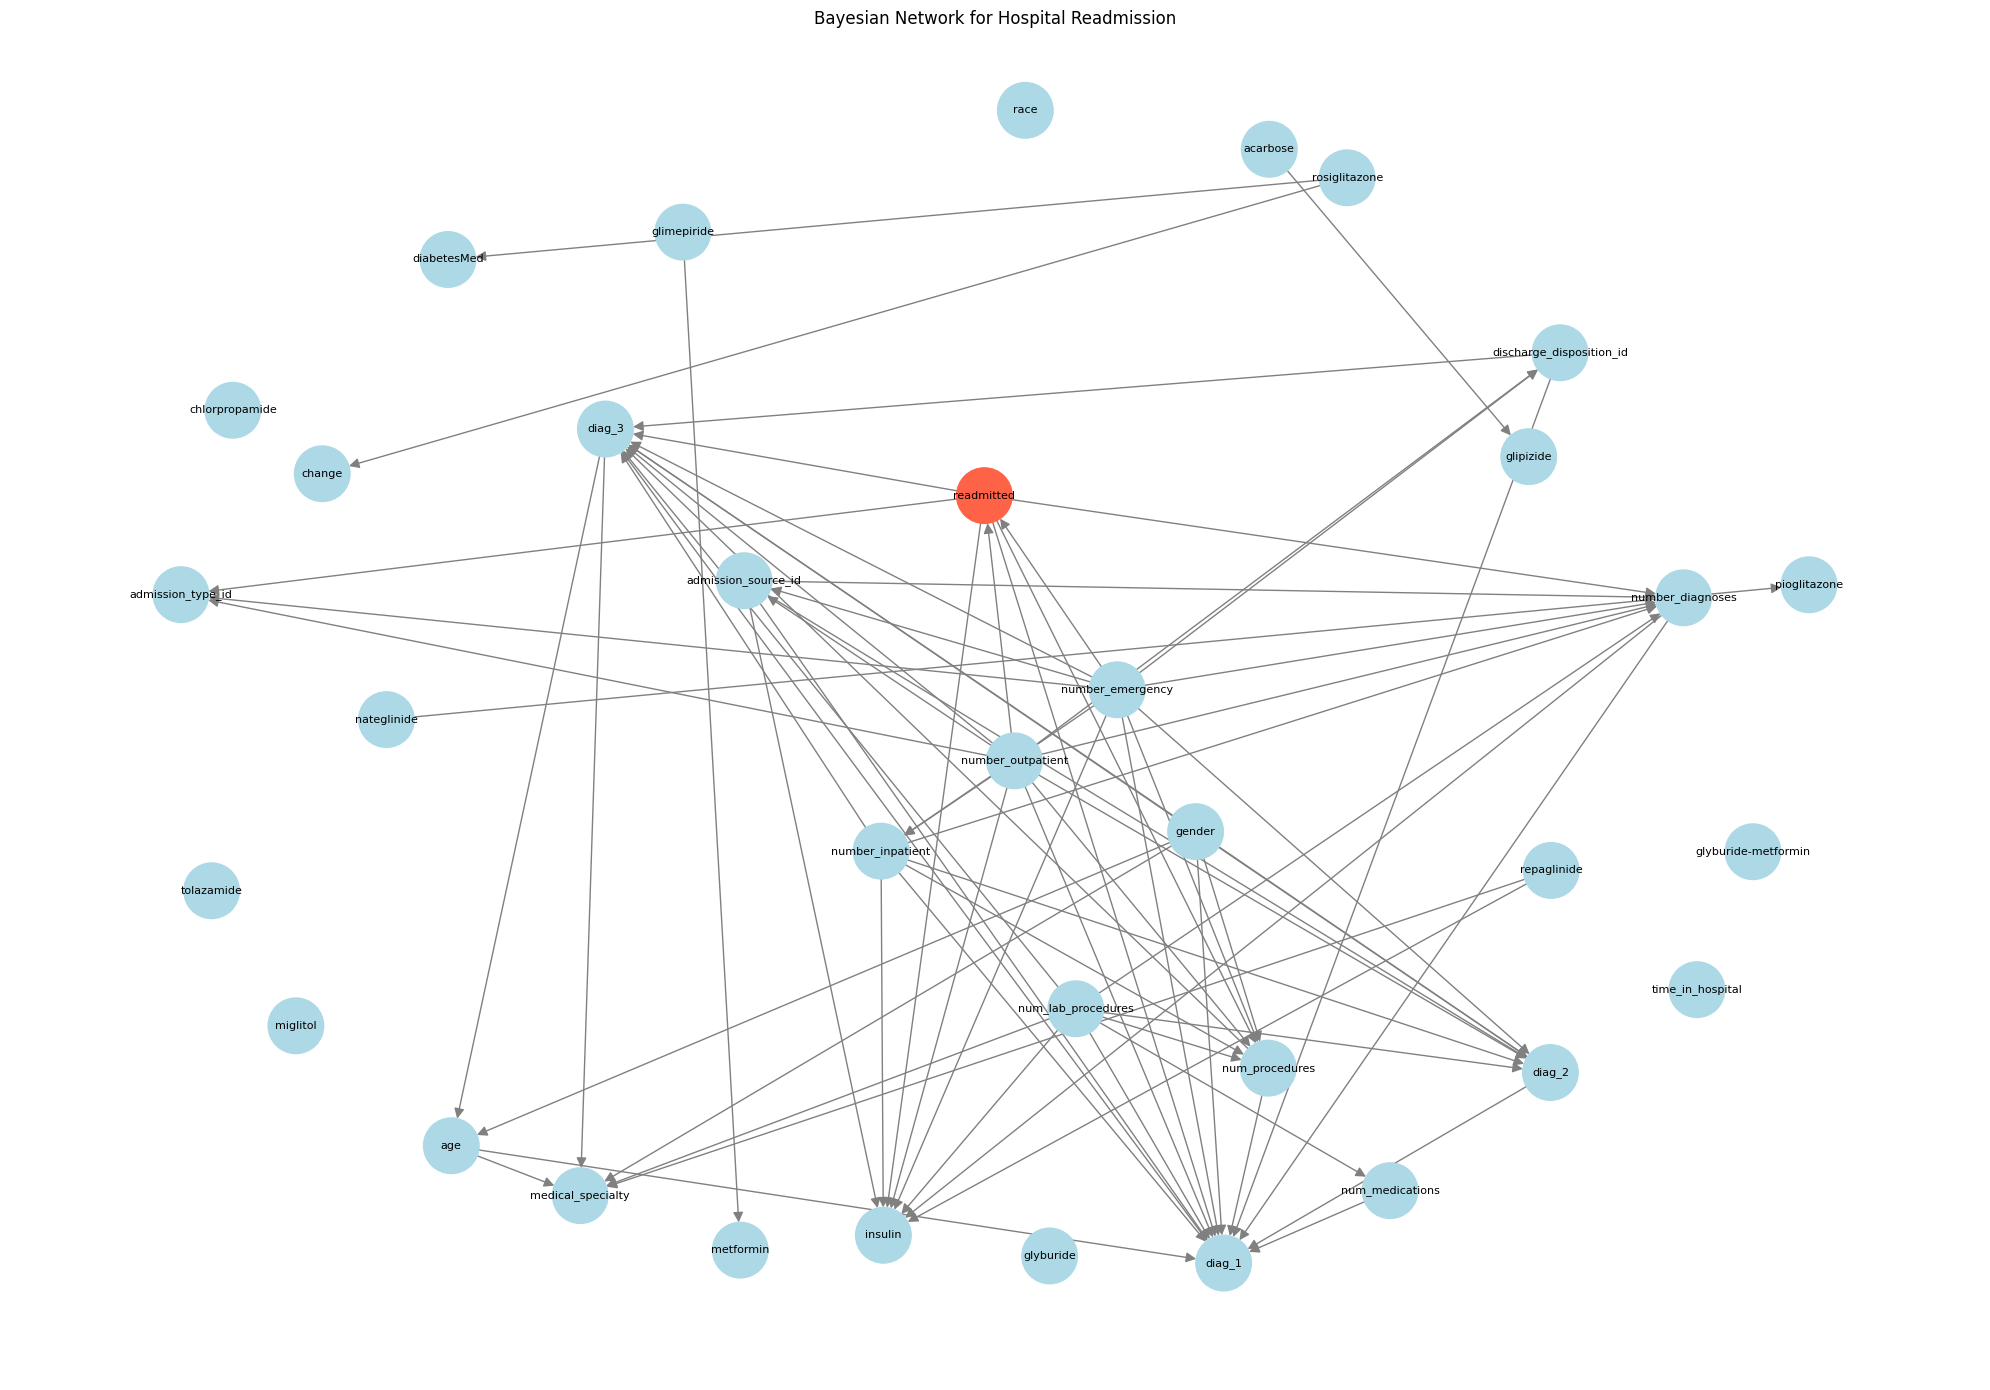

Parents of readmitted:
['number_emergency', 'number_outpatient']

Children of readmitted:
['insulin', 'diag_1', 'num_procedures', 'diag_3', 'admission_type_id', 'number_diagnoses']

Medical specialty relationships:
Parents: ['diag_3', 'age', 'num_lab_procedures', 'gender', 'repaglinide']
Children: []


In [22]:
# Create directed graph
G = nx.DiGraph()

G.add_nodes_from(train_bn.columns)
G.add_edges_from(pc_model.edges())

# Node positions
pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5
)

# Highlight target variable
node_colors = [
    'tomato' if node == 'readmitted'
    else 'lightblue'
    for node in G.nodes()
]

plt.figure(figsize=(20, 14))

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    node_size=1600,
    font_size=8,
    edge_color='gray',
    arrows=True,
    arrowsize=15
)

plt.title("Bayesian Network for Hospital Readmission")
plt.axis('off')
plt.tight_layout()
plt.show()

# Examine direct relationships
print("Parents of readmitted:")
print(list(G.predecessors('readmitted')))

print("\nChildren of readmitted:")
print(list(G.successors('readmitted')))

print("\nMedical specialty relationships:")
print("Parents:", list(G.predecessors('medical_specialty')))
print("Children:", list(G.successors('medical_specialty')))

# Step 13. Network Complexity Analysis

The learned network was analyzed to determine the number of parent variables and estimated conditional probability table entries for each node. Variables with many states or multiple parents can increase computational complexity considerably. This analysis helps determine whether the network can be fitted directly or whether additional simplification is necessary.

In [23]:
complexity_results = []

for node in G.nodes():

    parents = list(G.predecessors(node))
    number_states = train_bn[node].nunique()

    cpt_entries = number_states

    for parent in parents:
        cpt_entries *= train_bn[parent].nunique()

    complexity_results.append({
        'Variable': node,
        'Number of Parents': len(parents),
        'Number of States': number_states,
        'Estimated CPT Entries': cpt_entries
    })

complexity_df = pd.DataFrame(complexity_results)

complexity_df = complexity_df.sort_values(
    'Estimated CPT Entries',
    ascending=False
)

display(complexity_df)

print(
    f"Total estimated CPT entries: "
    f"{complexity_df['Estimated CPT Entries'].sum():,}"
)

print(
    f"Largest CPT: "
    f"{complexity_df['Estimated CPT Entries'].max():,}"
)

,Variable,Number of Parents,Number of States,Estimated CPT Entries
14,diag_1,14,19,397816787160
16,diag_3,9,19,13684788
7,medical_specialty,5,22,150480
30,insulin,8,4,132192
15,diag_2,6,19,78489
17,number_diagnoses,6,3,8262
9,num_procedures,6,3,1458
2,age,2,10,570
4,discharge_disposition_id,2,26,234
5,admission_source_id,2,17,153


Total estimated CPT entries: 397,830,844,107
Largest CPT: 397,816,787,160


# Step 14. Simplify the Bayesian Network
The original Bayesian Network contained 73 relationships between variables. To reduce computational complexity, mutual information was used to prioritize up to three parent relationships per variable, reducing the network to 40 edges. A total of 33 relationships were removed, representing approximately 45.2% of the original connections. This simplification maintains the original variables while reducing the complexity of the conditional probability tables.
This code uses mutual information to rank the existing parent relationships and retains at most three parents per node.This approach retains the original direction of each selected edge. 

In [25]:
from sklearn.metrics import mutual_info_score

max_parents = 3

# Create a simplified network
simplified_G = nx.DiGraph()
simplified_G.add_nodes_from(train_bn.columns)

removed_edges = []

for node in G.nodes():

    parents = list(G.predecessors(node))

    # Calculate mutual information for each existing parent
    parent_scores = []

    for parent in parents:

        score = mutual_info_score(
            train_bn[parent],
            train_bn[node]
        )

        parent_scores.append((parent, score))

    # Sort parents by strongest association
    parent_scores.sort(
        key=lambda x: x[1],
        reverse=True
    )

    # Keep up to three parents
    selected = parent_scores[:max_parents]

    for parent, score in selected:
        simplified_G.add_edge(parent, node)

    for parent, score in parent_scores[max_parents:]:
        removed_edges.append({
            'Parent': parent,
            'Child': node,
            'Mutual Information': score
        })

print("Original edges:", G.number_of_edges())
print("Simplified edges:", simplified_G.number_of_edges())

print("\nRemoved relationships:")
display(pd.DataFrame(removed_edges))

Original edges: 73
Simplified edges: 40

Removed relationships:


,Parent,Child,Mutual Information
0,gender,medical_specialty,0.007257
1,repaglinide,medical_specialty,0.004562
2,gender,num_procedures,0.001362
3,readmitted,num_procedures,0.001110
4,number_outpatient,num_procedures,0.000597
5,admission_source_id,diag_1,0.069563
6,age,diag_1,0.069508
7,discharge_disposition_id,diag_1,0.054190
8,num_medications,diag_1,0.033676
9,num_lab_procedures,diag_1,0.016574


# Step 15. Recalculating the CPT Sizes

Before fitting the simplified network, we'll calculate its complexity again. WIth this it was clear that the CPT size went incredibly down. From almost 40 billion entries on diag_1 variable to only 30k. This will allow this training model to not use all the resources provided and create a good predicting model with less computational power.

In [26]:
simplified_complexity = []

for node in simplified_G.nodes():

    parents = list(
        simplified_G.predecessors(node)
    )

    cpt_entries = train_bn[node].nunique()

    for parent in parents:
        cpt_entries *= train_bn[parent].nunique()

    simplified_complexity.append({
        'Variable': node,
        'Number of Parents': len(parents),
        'Estimated CPT Entries': cpt_entries
    })

simplified_complexity_df = pd.DataFrame(
    simplified_complexity
).sort_values(
    'Estimated CPT Entries',
    ascending=False
)

display(simplified_complexity_df)

print(
    f"Largest CPT: "
    f"{simplified_complexity_df['Estimated CPT Entries'].max():,}"
)

print(
    f"Total CPT entries: "
    f"{simplified_complexity_df['Estimated CPT Entries'].sum():,}"
)

,Variable,Number of Parents,Estimated CPT Entries
16,diag_3,3,28158
14,diag_1,3,20577
7,medical_specialty,3,12540
15,diag_2,3,2907
30,insulin,3,612
2,age,2,570
17,number_diagnoses,3,459
4,discharge_disposition_id,2,234
5,admission_source_id,2,153
3,admission_type_id,3,144


Largest CPT: 28,158
Total CPT entries: 66,612


# Step 16. Conditional Probability Estimation

The simplified Bayesian Network was fitted using the Bayesian Estimator from pgmpy. Conditional probability tables were calculated using a BDeu prior with an equivalent sample size of five and added to the network. This approach allows the model to estimate the probability distributions of the variables based on their parent relationships.

In [28]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
import time

# Create simplified Bayesian Network
bn_model = DiscreteBayesianNetwork(
    simplified_G.edges()
)

# Include all variables
bn_model.add_nodes_from(train_bn.columns)

print("Starting CPT estimation...")

start_time = time.time()

# Initialize Bayesian Estimator
estimator = BayesianEstimator(
    bn_model,
    train_bn
)

# Estimate CPTs using BDeu prior
cpds = estimator.get_parameters(
    prior_type='BDeu',
    equivalent_sample_size=5,
    n_jobs=1
)

# Add estimated CPTs to the model
bn_model.add_cpds(*cpds)

elapsed = time.time() - start_time

print("\nBayesian Network fitted successfully!")
print(f"Execution time: {elapsed:.2f} seconds")

# Validate model
print("Model valid:", bn_model.check_model())

print("\nNumber of nodes:", len(bn_model.nodes()))
print("Number of edges:", len(bn_model.edges()))

# Display readmission CPT
print("\nConditional Probability Table for readmitted:")
print(bn_model.get_cpds('readmitted'))

Starting CPT estimation...


C:\Users\manue\AppData\Local\Temp\ipykernel_4824\1783654768.py:18: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(



Bayesian Network fitted successfully!
Execution time: 0.44 seconds
Model valid: True

Number of nodes: 35
Number of edges: 40

Conditional Probability Table for readmitted:
+-------------------+-----+------------------------+
| number_emergency  | ... | number_emergency(One)  |
+-------------------+-----+------------------------+
| number_outpatient | ... | number_outpatient(One) |
+-------------------+-----+------------------------+
| readmitted(0)     | ... | 0.3805960764587525     |
+-------------------+-----+------------------------+
| readmitted(1)     | ... | 0.6194039235412475     |
+-------------------+-----+------------------------+


# Step 17. Readmission Probability Results

The Bayesian Network showed that patients with more previous emergency visits generally had higher estimated probabilities of hospital readmission. The highest probability was 76.48% for patients with multiple emergency visits and one outpatient visit, while the lowest was 41.98% for patients with no previous emergency or outpatient visits. These results suggest that previous hospital utilization is associated with readmission, although the relationships do not necessarily indicate causation.

In [30]:
from itertools import product

# Get readmission CPT
readmission_cpt = bn_model.get_cpds('readmitted')

# Obtain parent variables and their possible states
parents = list(readmission_cpt.variables[1:])

parent_states = [
    readmission_cpt.state_names[parent]
    for parent in parents
]

results = []

# Calculate probability for every parent combination
for combination in product(*parent_states):

    evidence = dict(zip(parents, combination))

    probability = readmission_cpt.get_value(
        readmitted='1',
        **evidence
    )

    results.append({
        **evidence,
        'Readmission Probability': probability
    })

# Create results table
probability_df = pd.DataFrame(results)

probability_df = probability_df.sort_values(
    'Readmission Probability',
    ascending=False
)

# Create a formatted copy for display
probability_display = probability_df.copy()

probability_display['Readmission Probability'] = (
    probability_display['Readmission Probability']
    .map(lambda x: f"{x:.2%}")
)

display(probability_display)

,number_emergency,number_outpatient,Readmission Probability
2,Multiple,One,76.48%
0,Multiple,Multiple,76.20%
1,Multiple,None,69.29%
6,One,Multiple,66.43%
8,One,One,61.94%
7,One,None,57.35%
3,None,Multiple,56.13%
5,None,One,54.65%
4,None,None,41.98%


# Step 18. Generating Readmission Predictions

The Bayesian Network's conditional probability table was used to estimate readmission probabilities for observations in the testing dataset. Predictions were generated using the two direct parent variables of readmitted, which were previous emergency and outpatient visits. A probability threshold of 0.50 was applied to classify each observation as readmitted or not readmitted, allowing the predicted outcomes to be compared with the actual results.

In [31]:
# Get readmission CPT
readmission_cpt = bn_model.get_cpds('readmitted')

# Identify the parent variables
parents = list(readmission_cpt.variables[1:])

print("Predictor variables:", parents)

# Prepare testing data
evaluation_df = test_bn.copy()

# Calculate readmission probabilities
def predict_readmission(row):

    evidence = {
        parent: row[parent]
        for parent in parents
    }

    probability = readmission_cpt.get_value(
        readmitted='1',
        **evidence
    )

    return float(probability)

evaluation_df['Readmission Probability'] = (
    evaluation_df.apply(
        predict_readmission,
        axis=1
    )
)

# Convert probabilities into binary predictions
evaluation_df['Predicted Readmission'] = (
    evaluation_df['Readmission Probability'] >= 0.50
).astype(int)

# Actual readmission values
evaluation_df['Actual Readmission'] = (
    evaluation_df['readmitted'].astype(int)
)

# Display prediction results
display(
    evaluation_df[
        [
            'number_emergency',
            'number_outpatient',
            'Readmission Probability',
            'Predicted Readmission',
            'Actual Readmission'
        ]
    ].head(15)
)

Predictor variables: ['number_emergency', 'number_outpatient']


,number_emergency,number_outpatient,Readmission Probability,Predicted Readmission,Actual Readmission
28983,None,None,0.419784,0,1
75346,None,One,0.546518,1,0
2323,None,None,0.419784,0,0
3946,None,None,0.419784,0,1
22791,None,None,0.419784,0,1
62142,Multiple,Multiple,0.762047,1,0
3001,None,One,0.546518,1,0
28101,None,None,0.419784,0,0
57899,Multiple,None,0.692946,1,0
35637,One,None,0.573485,1,0


# Step 19. Model Performance Evaluation

The Bayesian Network predictions were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and average precision. These metrics were calculated using the testing dataset to determine how well the model distinguishes between readmitted and non-readmitted patients. Particular attention was given to recall and precision because incorrectly identifying patients who may require additional medical attention could affect the usefulness of the prediction model.

In [32]:
# Actual and predicted outcomes
y_true = evaluation_df['Actual Readmission']
y_pred = evaluation_df['Predicted Readmission']
y_prob = evaluation_df['Readmission Probability']

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)
avg_precision = average_precision_score(y_true, y_prob)

# Display results
metrics_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score',
        'ROC-AUC',
        'Average Precision'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        avg_precision
    ]
})

metrics_df['Score'] = metrics_df['Score'].map(
    lambda x: f"{x:.2f}"
)

display(metrics_df)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            'Not Readmitted',
            'Readmitted'
        ],
        zero_division=0
    )
)

,Metric,Score
0,Accuracy,0.58
1,Precision,0.59
2,Recall,0.30
3,F1-score,0.40
4,ROC-AUC,0.56
5,Average Precision,0.51



Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.58      0.82      0.68     10973
    Readmitted       0.59      0.30      0.40      9381

      accuracy                           0.58     20354
     macro avg       0.58      0.56      0.54     20354
  weighted avg       0.58      0.58      0.55     20354



# Step 20. Confusion Matrix Analysis

A confusion matrix was generated to compare the predicted readmission outcomes with the actual testing results. The matrix separates correct predictions into true positives and true negatives, while incorrect predictions are represented by false positives and false negatives. This allows us to examine whether the Bayesian Network is more effective at identifying readmitted or non-readmitted patients and determine which classification errors occur most frequently.

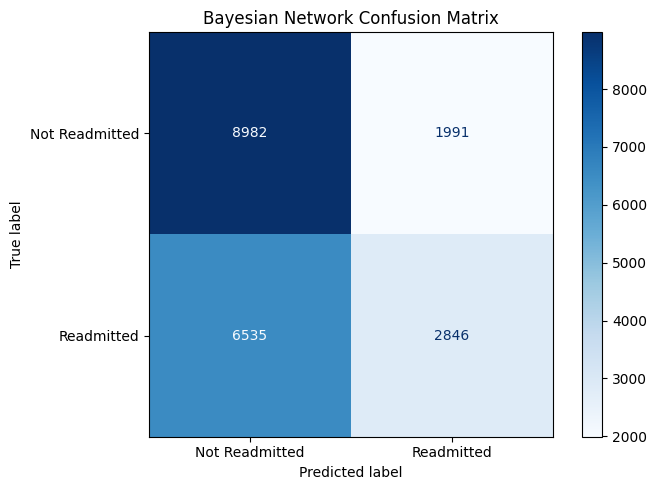

True Negatives: 8,982
False Positives: 1,991
False Negatives: 6,535
True Positives: 2,846


In [33]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Display matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'Not Readmitted',
        'Readmitted'
    ]
).plot(
    ax=ax,
    cmap='Blues',
    values_format='d'
)

plt.title("Bayesian Network Confusion Matrix")
plt.tight_layout()
plt.show()

# Print classification counts
tn, fp, fn, tp = cm.ravel()

print(f"True Negatives: {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives: {tp:,}")

# Step 21. ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve was generated to evaluate the model's ability to distinguish between patients who were readmitted and those who were not. The curve compares the true positive rate against the false positive rate across different classification thresholds. The area under the curve (ROC-AUC) summarizes the model's overall discrimination performance, with higher values indicating better separation between the two classes.

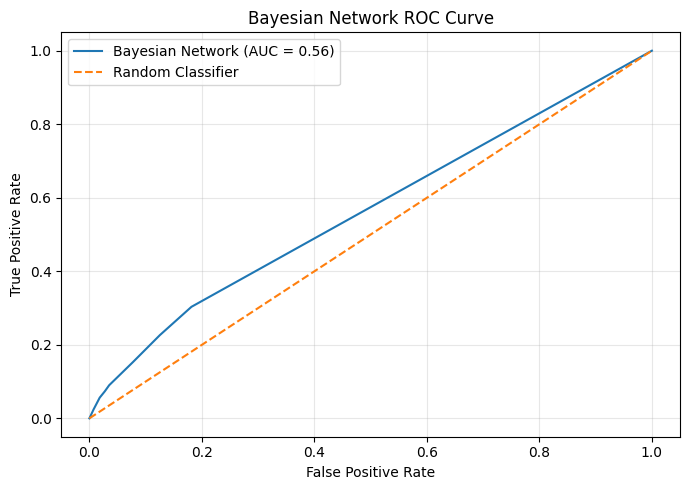

In [35]:
from sklearn.metrics import roc_curve

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Bayesian Network (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Bayesian Network ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 22. Baseline Comparison

The Bayesian Network was compared with a baseline classifier that always predicts the most common readmission category in the training dataset. This comparison helps determine whether the Bayesian Network provides an improvement over a simple classification strategy. Although accuracy is useful, the other evaluation metrics are also necessary to assess whether the model can reliably identify patients who are readmitted.

In [34]:
# Identify majority class in training
majority_class = int(
    train_bn['readmitted'].mode().iloc[0]
)

# Generate baseline predictions
baseline_predictions = np.full(
    len(y_true),
    majority_class
)

# Compare accuracy
baseline_accuracy = accuracy_score(
    y_true,
    baseline_predictions
)

print(f"Baseline Accuracy: {baseline_accuracy:.2f}")
print(f"Bayesian Network Accuracy: {accuracy:.2f}")
print(f"Accuracy Difference: {accuracy - baseline_accuracy:+.2f}")

Baseline Accuracy: 0.54
Bayesian Network Accuracy: 0.58
Accuracy Difference: +0.04


# Step 23. Bayesian Network Evaluation Results

The Bayesian Network achieved an accuracy of 58%, precision of 59%, recall of 30%, F1-score of 40%, and ROC-AUC of 0.56. Although the model performed slightly better than the baseline accuracy of 54%, the confusion matrix showed that it failed to identify 6,535 patients who were actually readmitted. The ROC curve also indicated limited discrimination between readmitted and non-readmitted patients. These results suggest that using only previous emergency and outpatient visits is not sufficient for reliable readmission prediction, and additional patient characteristics or improvements to the model may be necessary.